In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Retail store sales data

In [79]:
df=pd.read_csv(r"C:\Users\VAMSHI\Downloads\archive (1)\retail_store_sales.csv")

In [80]:
df.head(20)

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False
5,TXN_7482416,CUST_09,Patisserie,NaN,NaN,10.0,200.0,Credit Card,Online,2023-11-30,NaN
6,TXN_3652209,CUST_07,Food,Item_1_FOOD,5.0,8.0,40.0,Credit Card,In-store,2023-06-10,True
7,TXN_1372952,CUST_21,Furniture,NaN,33.5,NaN,NaN,Digital Wallet,In-store,2024-04-02,True
8,TXN_9728486,CUST_23,Furniture,Item_16_FUR,27.5,1.0,27.5,Credit Card,In-store,2023-04-26,False
9,TXN_2722661,CUST_25,Butchers,Item_22_BUT,36.5,3.0,109.5,Cash,Online,2024-03-14,False


In [81]:
df.isnull().sum() #it is counts missing values in every column

Transaction ID         0
Customer ID            0
Category               0
Item                1213
Price Per Unit       609
Quantity             604
Total Spent          604
Payment Method         0
Location               0
Transaction Date       0
Discount Applied    4199
dtype: int64

In [82]:
missing_percentages=(df.isnull().sum()/len(df))*100
missing_percentages

Transaction ID       0.000000
Customer ID          0.000000
Category             0.000000
Item                 9.646123
Price Per Unit       4.842942
Quantity             4.803181
Total Spent          4.803181
Payment Method       0.000000
Location             0.000000
Transaction Date     0.000000
Discount Applied    33.391650
dtype: float64

In [83]:
df.shape# to check the rows and col in data set

(12575, 11)

In [84]:
df.columns # it is shows the all columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied'],
      dtype='str')

In [85]:
df.info() # display columns names ,data types and non-null values

<class 'pandas.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    12575 non-null  str    
 1   Customer ID       12575 non-null  str    
 2   Category          12575 non-null  str    
 3   Item              11362 non-null  str    
 4   Price Per Unit    11966 non-null  float64
 5   Quantity          11971 non-null  float64
 6   Total Spent       11971 non-null  float64
 7   Payment Method    12575 non-null  str    
 8   Location          12575 non-null  str    
 9   Transaction Date  12575 non-null  str    
 10  Discount Applied  8376 non-null   object 
dtypes: float64(3), object(1), str(7)
memory usage: 1.1+ MB


In [86]:
df.describe() # it is generate the statistical summary for numerical columns

,Price Per Unit,Quantity,Total Spent
count,11966.000000,11971.000000,11971.000000
mean,23.365912,5.536380,129.652577
std,10.743519,2.857883,94.750697
min,5.000000,1.000000,5.000000
25%,14.000000,3.000000,51.000000
50%,23.000000,6.000000,108.500000
75%,33.500000,8.000000,192.000000
max,41.000000,10.000000,410.000000


# Handling missing values  for numerical columns

In [87]:
df['Price Per Unit']=df['Price Per Unit'].fillna(df['Price Per Unit'].median()) # filling missing price using the median price

In [88]:
df['Quantity']=df['Quantity'].fillna(df['Quantity'].median()) # filling missing Quantity using the median Quantity

In [89]:
df['Total Spent']=df['Total Spent'].fillna(df['Total Spent'].median()) #filling missing Total Spending using the median Total Spending

In [90]:
df.isna().sum()

Transaction ID         0
Customer ID            0
Category               0
Item                1213
Price Per Unit         0
Quantity               0
Total Spent            0
Payment Method         0
Location               0
Transaction Date       0
Discount Applied    4199
dtype: int64

In [91]:
df['Item']=df['Item'].fillna('Unknown') # replacing missing item name with Unknown

In [92]:
df['Discount Applied']=df['Discount Applied'].fillna('No') # filling missing discount amount information with No

In [93]:
df.isna().sum()

Transaction ID      0
Customer ID         0
Category            0
Item                0
Price Per Unit      0
Quantity            0
Total Spent         0
Payment Method      0
Location            0
Transaction Date    0
Discount Applied    0
dtype: int64

In [94]:
df.duplicated().sum() # to find the duplicated data in the data set  and sum it shows ,in my data no duplicated data are there so it showing Zero(0)

np.int64(0)

In [95]:
df['Category']

0           Patisserie
1        Milk Products
2             Butchers
3            Beverages
4                 Food
             ...      
12570       Patisserie
12571        Beverages
12572         Butchers
12573        Furniture
12574             Food
Name: Category, Length: 12575, dtype: str

In [96]:
df['Category'].unique() # it is displays all unique product Category

<StringArray>
[                        'Patisserie',                      'Milk Products',
                           'Butchers',                          'Beverages',
                               'Food',                          'Furniture',
      'Electric household essentials', 'Computers and electric accessories']
Length: 8, dtype: str

In [97]:
df['Payment Method'].unique() # it is displays all unique payment method

<StringArray>
['Digital Wallet', 'Credit Card', 'Cash']
Length: 3, dtype: str

In [98]:
df['Location'].unique()

<StringArray>
['Online', 'In-store']
Length: 2, dtype: str

### Outliers Detection 

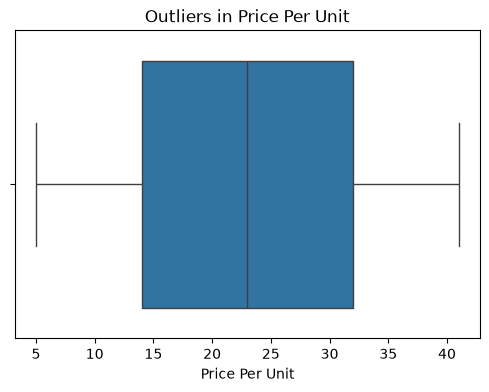

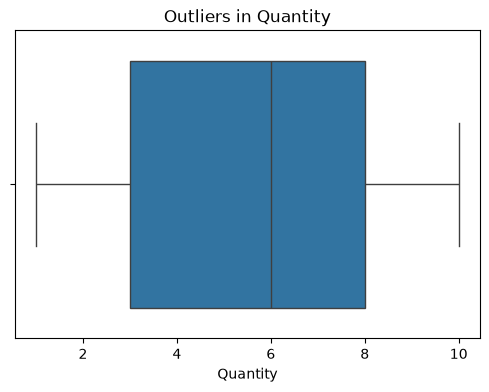

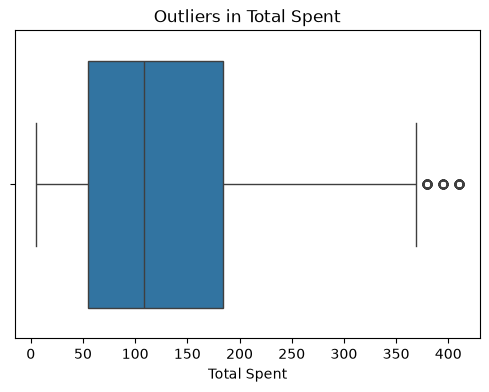

In [99]:
# Checking outliers in Price Per Unit
plt.figure(figsize=(6, 4))

sns.boxplot(x=df["Price Per Unit"])

plt.title("Outliers in Price Per Unit")
plt.xlabel("Price Per Unit")

plt.show()


# Checking outliers in Quantity
plt.figure(figsize=(6, 4))

sns.boxplot(x=df["Quantity"])

plt.title("Outliers in Quantity")
plt.xlabel("Quantity")

plt.show()


# Checking outliers in Total Spent
plt.figure(figsize=(6, 4))

sns.boxplot(x=df["Total Spent"])

plt.title("Outliers in Total Spent")
plt.xlabel("Total Spent")

plt.show()

### Outliers Treatment

In [100]:
from feature_engine.outliers import Winsorizer

In [101]:
win = Winsorizer(capping_method='iqr',tail='both')

In [102]:
df = win.fit_transform(df)

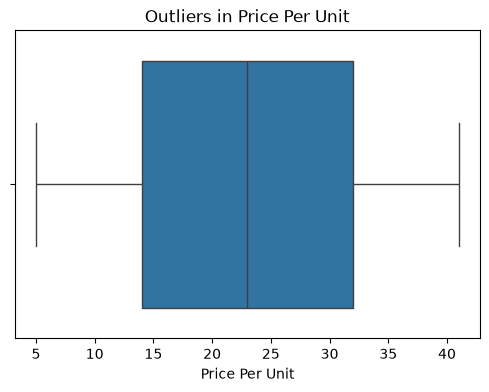

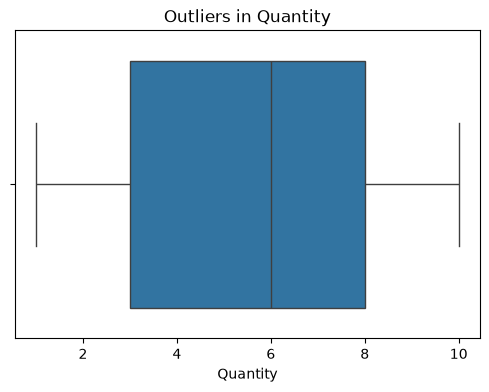

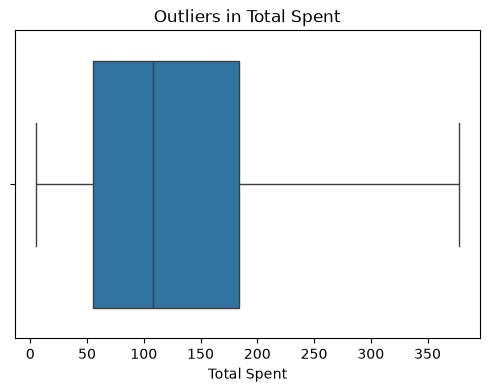

In [103]:
# Checking outliers in Price Per Unit
plt.figure(figsize=(6, 4))
sns.boxplot(x=df["Price Per Unit"])
plt.title("Outliers in Price Per Unit")
plt.xlabel("Price Per Unit")
plt.show()
# Checking outliers in Quantity
plt.figure(figsize=(6, 4))
sns.boxplot(x=df["Quantity"])
plt.title("Outliers in Quantity")
plt.xlabel("Quantity")
plt.show()
# Checking outliers in Total Spent
plt.figure(figsize=(6, 4))
sns.boxplot(x=df["Total Spent"])
plt.title("Outliers in Total Spent")
plt.xlabel("Total Spent")
plt.show()

# Data manipulation 

### Converting Transaction Data

In [104]:
df['Transaction Date'].dtype #checking the current data types of transaction date

<StringDtype(storage='python', na_value=nan)>

In [105]:
df['Transaction Date']=pd.to_datetime(df['Transaction Date']) # convert transaction date from text to datetime format

datetime format allows us to extract
* year
* month
* day
* day of week

# creating year column

In [106]:
df['Year']=df['Transaction Date'].dt.year

In [107]:
df[['Transaction Date','Year']].head()

,Transaction Date,Year
0,2024-04-08,2024
1,2023-07-23,2023
2,2022-10-05,2022
3,2022-05-07,2022
4,2022-10-02,2022


# creating  month column

In [108]:
df['Month']=df['Transaction Date'].dt.month

In [109]:
df[['Transaction Date','Month']].head()

,Transaction Date,Month
0,2024-04-08,4
1,2023-07-23,7
2,2022-10-05,10
3,2022-05-07,5
4,2022-10-02,10


# creating month name

In [110]:
df['Month_Name']=df['Transaction Date'].dt.month_name()

In [111]:
df['Month_Name']

0            April
1             July
2          October
3              May
4          October
           ...    
12570    September
12571       August
12572       August
12573     December
12574       August
Name: Month_Name, Length: 12575, dtype: str

### Calculate Total Amount

In [112]:
df["Calculated Amount"] = (
    df["Price Per Unit"] * df["Quantity"]
)

### Compare calculated amount with Total Spent

In [113]:
df["Calculated Amount"] = (
    df["Price Per Unit"] * df["Quantity"]
)

df[df["Calculated Amount"] != df["Total Spent"]]

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied,Year,Month,Month_Name,Calculated Amount
5,TXN_7482416,CUST_09,Patisserie,Unknown,23.0,10.0,200.0,Credit Card,Online,2023-11-30,No,2023,11,November,230.0
7,TXN_1372952,CUST_21,Furniture,Unknown,33.5,6.0,108.5,Digital Wallet,In-store,2024-04-02,True,2024,4,April,201.0
11,TXN_5422631,CUST_09,Milk Products,Unknown,23.0,8.0,52.0,Digital Wallet,In-store,2025-01-12,True,2025,1,January,184.0
15,TXN_1809665,CUST_14,Beverages,Unknown,24.5,6.0,108.5,Credit Card,In-store,2022-05-11,No,2022,5,May,147.0
17,TXN_9634894,CUST_15,Milk Products,Unknown,23.0,10.0,275.0,Digital Wallet,Online,2022-04-17,No,2022,4,April,230.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12552,TXN_4823896,CUST_05,Milk Products,Unknown,8.0,6.0,108.5,Cash,In-store,2022-07-21,False,2022,7,July,48.0
12556,TXN_4397672,CUST_04,Beverages,Unknown,41.0,6.0,108.5,Credit Card,Online,2024-11-28,True,2024,11,November,246.0
12557,TXN_7239201,CUST_24,Beverages,Item_25_BEV,41.0,10.0,377.5,Digital Wallet,In-store,2024-05-01,False,2024,5,May,410.0
12562,TXN_7422454,CUST_07,Butchers,Unknown,33.5,6.0,108.5,Cash,Online,2023-04-15,No,2023,4,April,201.0


### Create a High/Low Spending category

In [114]:
df["Spending Level"] = np.where(
    df["Total Spent"] >= 200,
    "High Spending",
    "Low Spending"
)

### Create Quantity Category

In [115]:
df["Spending Level"] = np.where(
    df["Total Spent"] >= 200,
    "High Spending",
    "Low Spending"
)

In [116]:
df = df[df["Item"] != "Unknown"]

# Univariate Analysis

## 1. Quantity – Distribution

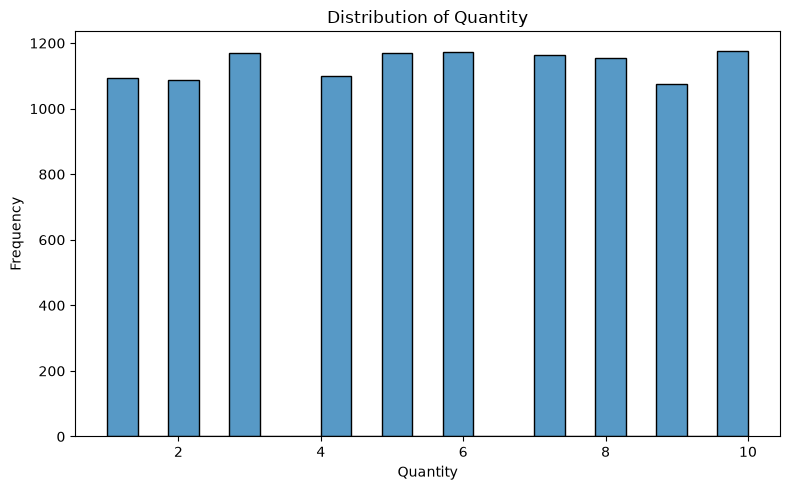

In [117]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Quantity"])

plt.title("Distribution of Quantity")
plt.xlabel("Quantity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

Insights : 
The histogram shows how frequently different quantities are purchased. Most transactions are concentrated around the common purchase quantities, while extreme quantities have been controlled using Winsorization.

## 2. Price Per Unit – Distribution

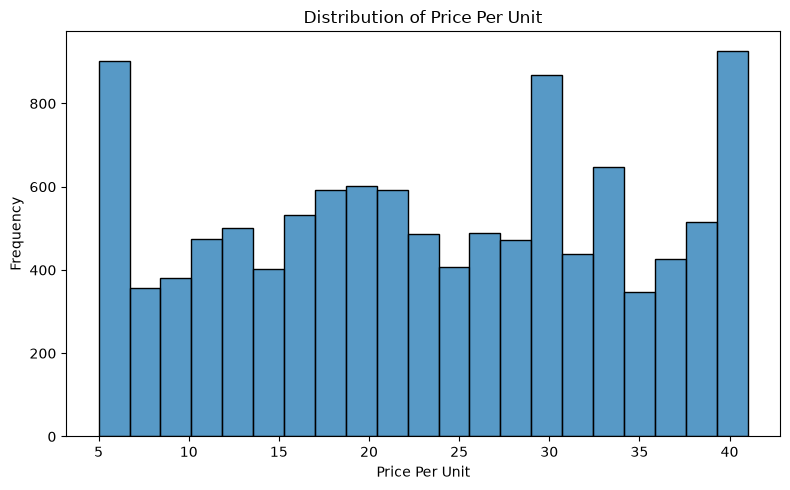

In [118]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Price Per Unit"])

plt.title("Distribution of Price Per Unit")
plt.xlabel("Price Per Unit")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

The plot shows the distribution of product prices. Most transactions fall within the common price range, while extreme prices have been capped using Winsorization.

## 3. Total Spent – Distribution

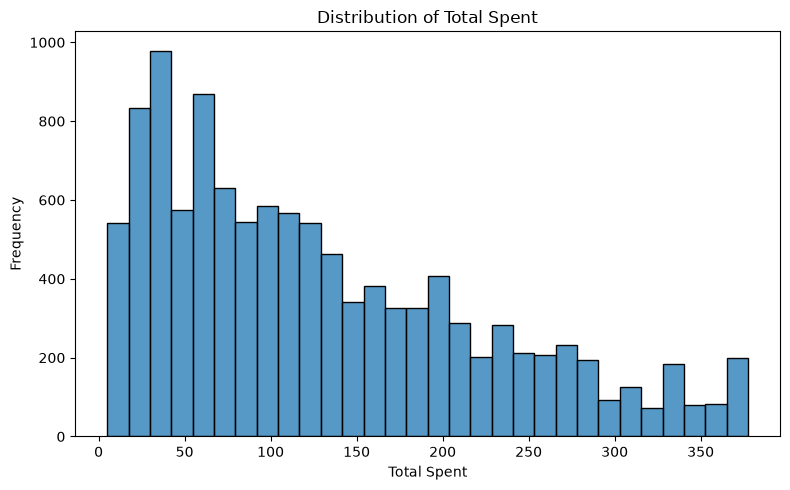

In [119]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Total Spent"])

plt.title("Distribution of Total Spent")
plt.xlabel("Total Spent")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

The histogram shows the distribution of customer spending per transaction. Most transactions are concentrated in the normal spending range, while extreme spending values have been controlled.

## 4. Category – Frequency

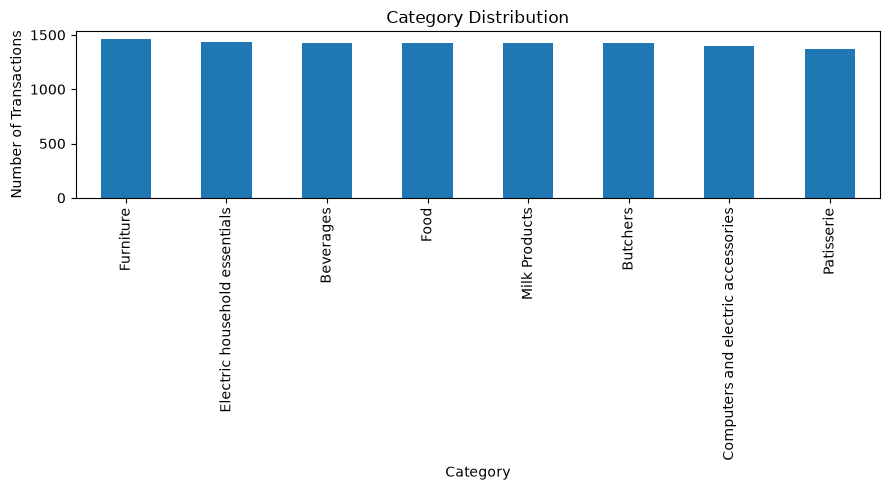

In [120]:
plt.figure(figsize=(9, 5))

df["Category"].value_counts().plot(kind="bar")

plt.title("Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

The countplot shows how transactions are distributed across product categories. Categories with higher transaction counts represent more frequently purchased product groups.

## 5. Item – Top 10 Frequency

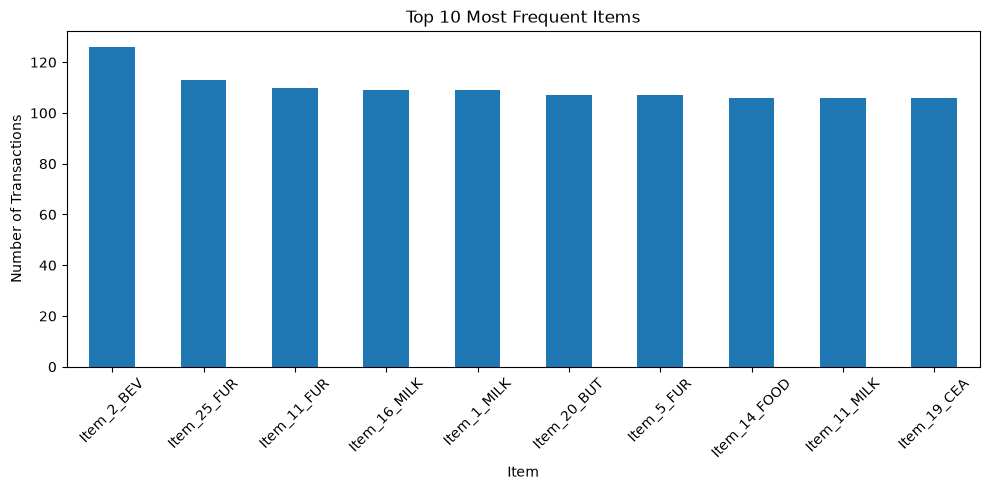

In [121]:
plt.figure(figsize=(10, 5))

df["Item"].value_counts().head(10).plot(kind="bar")

plt.title("Top 10 Most Frequent Items")
plt.xlabel("Item")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

The plot identifies the 10 items that appear most frequently in transactions. These items can be monitored closely for inventory and customer demand.

## 6. Location – Frequency

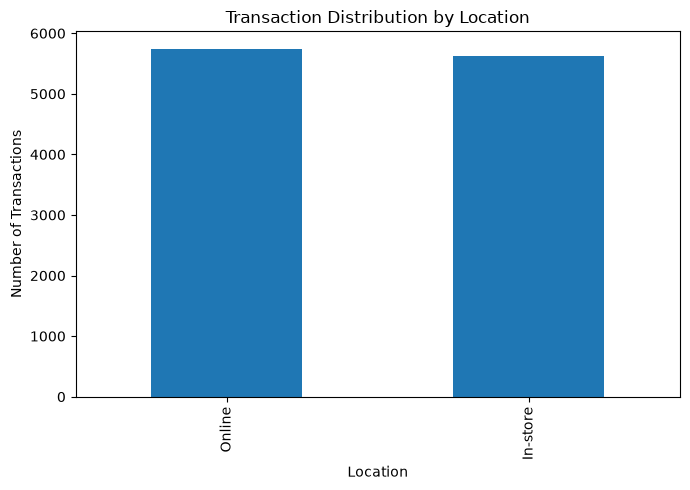

In [122]:
plt.figure(figsize=(7, 5))

df["Location"].value_counts().plot(kind="bar")

plt.title("Transaction Distribution by Location")
plt.xlabel("Location")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

The plot compares the number of transactions between Online and In-store channels. It shows how customers are distributed across the two sales channels.

## 7. Payment Method – Frequency

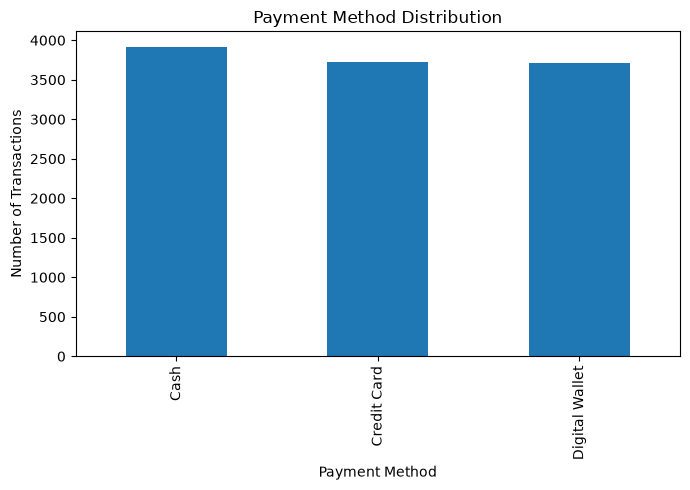

In [123]:
plt.figure(figsize=(7, 5))

df["Payment Method"].value_counts().plot(kind="bar")

plt.title("Payment Method Distribution")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

The plot shows customer payment preferences. The most frequently used payment method represents the dominant transaction method in the dataset.

# Business Problems

# 1. Identify High-Demand Products

#### Which products are selling the most, and which products should receive more inventory?

In [124]:
df.info()

<class 'pandas.DataFrame'>
Index: 11362 entries, 0 to 12574
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Transaction ID     11362 non-null  str           
 1   Customer ID        11362 non-null  str           
 2   Category           11362 non-null  str           
 3   Item               11362 non-null  str           
 4   Price Per Unit     11362 non-null  float64       
 5   Quantity           11362 non-null  float64       
 6   Total Spent        11362 non-null  float64       
 7   Payment Method     11362 non-null  str           
 8   Location           11362 non-null  str           
 9   Transaction Date   11362 non-null  datetime64[us]
 10  Discount Applied   11362 non-null  object        
 11  Year               11362 non-null  int32         
 12  Month              11362 non-null  int32         
 13  Month_Name         11362 non-null  str           
 14  Calculated Amount  113

In [125]:
# Find total quantity sold for each product
top_10_products = (
    df.groupby("Item")["Quantity"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print(top_10_products)

Item
Item_2_BEV      676.0
Item_16_MILK    627.0
Item_25_FUR     616.0
Item_19_MILK    589.0
Item_5_FUR      581.0
Item_13_FOOD    581.0
Item_1_MILK     578.0
Item_11_MILK    574.0
Item_11_FUR     573.0
Item_14_FOOD    566.0
Name: Quantity, dtype: float64


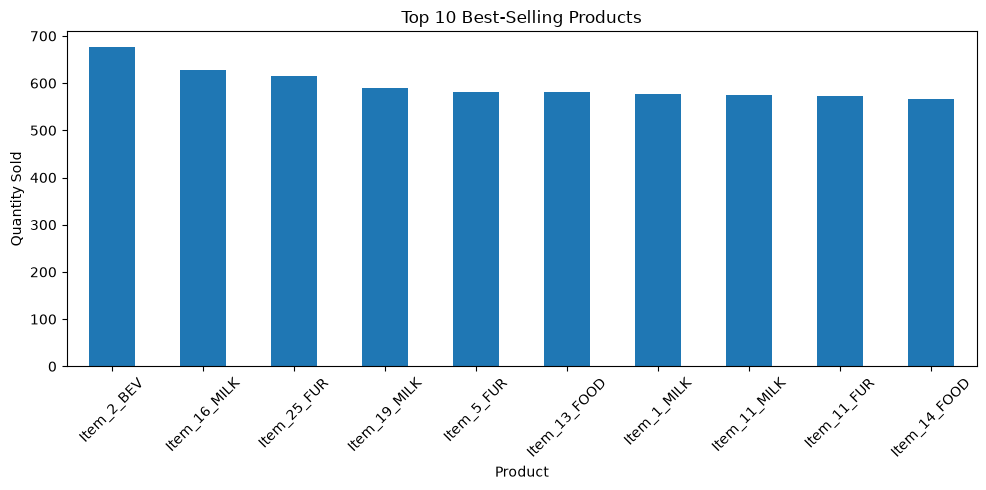

In [126]:
plt.figure(figsize=(10, 5))

top_10_products.plot(kind="bar")

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Product")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Insight
* The plot identifies the top 10 products based on quantity sold.
* The highest-selling product has the greatest customer demand.
* These products should be monitored carefully to avoid stock shortages.
* The business can maintain higher inventory for high-demand products.

# 2. Identify High-Performing Product Categories

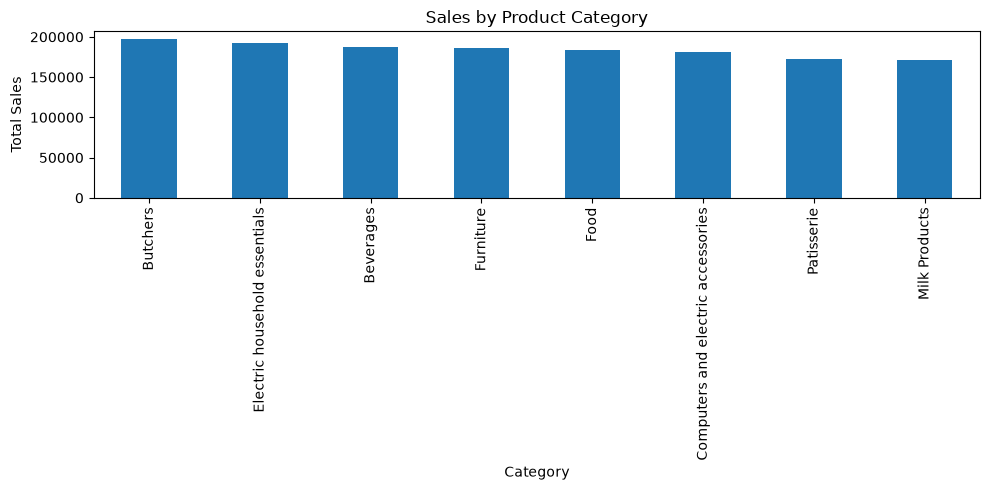

In [127]:
category_sales = df.groupby("Category")["Total Spent"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))

category_sales.plot(kind="bar")

plt.title("Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

## Insight
* The plot compares revenue generated by each category.
* Butchers has the highest category sales in your current results.
* Furniture has relatively lower sales.
* The business can focus promotions and inventory planning according to category performance.

# 3. Compare Online vs In-Store Sales

In [128]:
df.info()

<class 'pandas.DataFrame'>
Index: 11362 entries, 0 to 12574
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Transaction ID     11362 non-null  str           
 1   Customer ID        11362 non-null  str           
 2   Category           11362 non-null  str           
 3   Item               11362 non-null  str           
 4   Price Per Unit     11362 non-null  float64       
 5   Quantity           11362 non-null  float64       
 6   Total Spent        11362 non-null  float64       
 7   Payment Method     11362 non-null  str           
 8   Location           11362 non-null  str           
 9   Transaction Date   11362 non-null  datetime64[us]
 10  Discount Applied   11362 non-null  object        
 11  Year               11362 non-null  int32         
 12  Month              11362 non-null  int32         
 13  Month_Name         11362 non-null  str           
 14  Calculated Amount  113

In [129]:
location_sales = (
    df.groupby("Location")["Total Spent"]
      .sum()
      .sort_values(ascending=False)
)

print(location_sales)

Location
Online      748071.0
In-store    722307.5
Name: Total Spent, dtype: float64


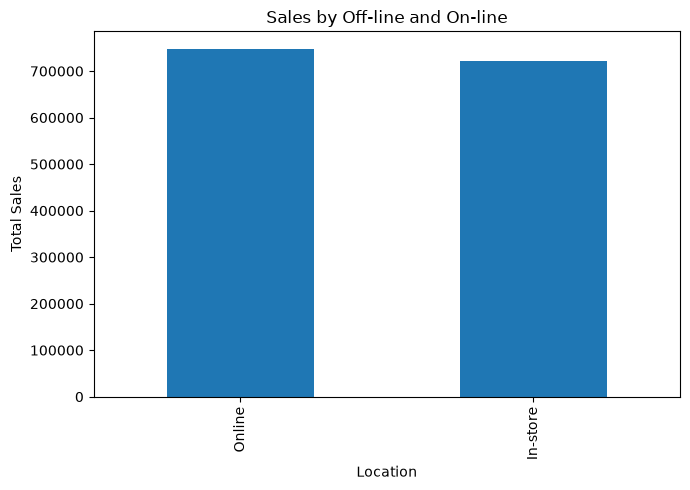

In [130]:
plt.figure(figsize=(7, 5))
location_sales.plot(kind="bar")
plt.title("Sales by Off-line and On-line")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

## Insight
* Online sales are slightly higher than In-store sales.
* This indicates that the online channel is an important revenue source.
* The business can continue improving online promotions and customer experience.

# 4. Identify Monthly Sales Patterns

#### Which months have relatively high or low sales?


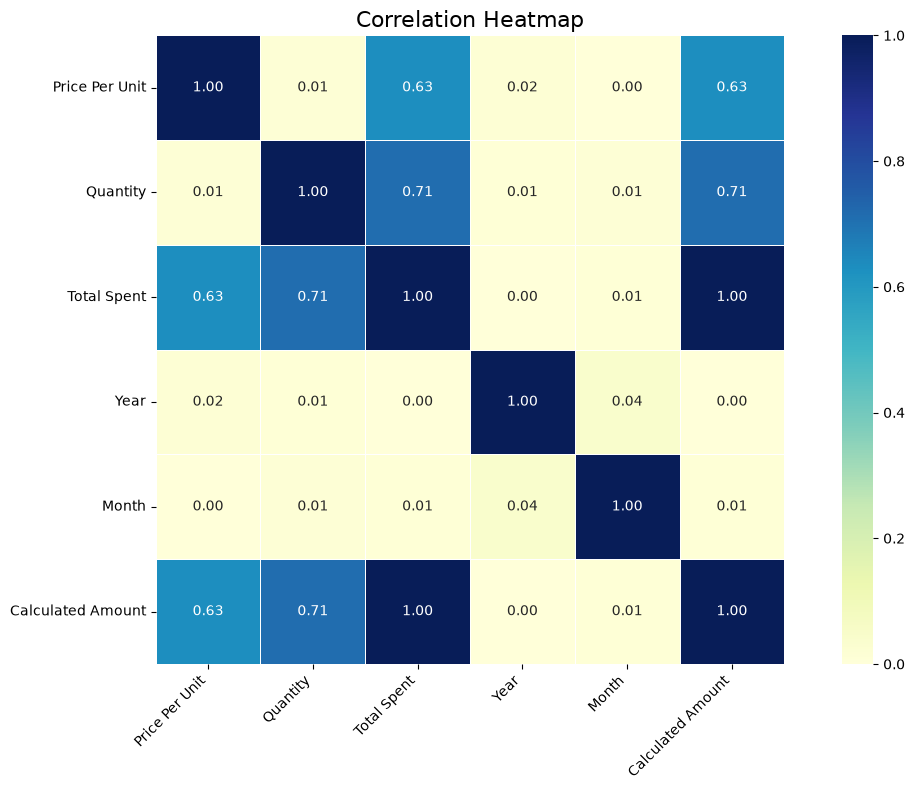

In [131]:
# Select numerical columns
numeric_df = df.select_dtypes(include='number')

# Calculate correlation
corr = numeric_df.corr()

# Convert correlations to absolute values
corr = corr.abs()

# Plot heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    square=True
)

plt.title("Correlation Heatmap", fontsize=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Insight
* Diagonal values are 1.00, showing that every variable has a perfect correlation with itself.
Quantity and Total Spent show a strong positive relationship — higher quantities generally lead to higher customer spending.
Price Per Unit and Total Spent are positively related, meaning changes in product price can influence the total transaction value.
Values close to 0 indicate weak relationships, meaning those variables have little linear relationship with each other.
The correlation analysis can support business decisions such as quantity-based promotions, bulk offers, and sales planning.

# 5. Understand the Relationship Between Quantity and Spending

#### Does purchasing more quantity lead to higher customer spending?

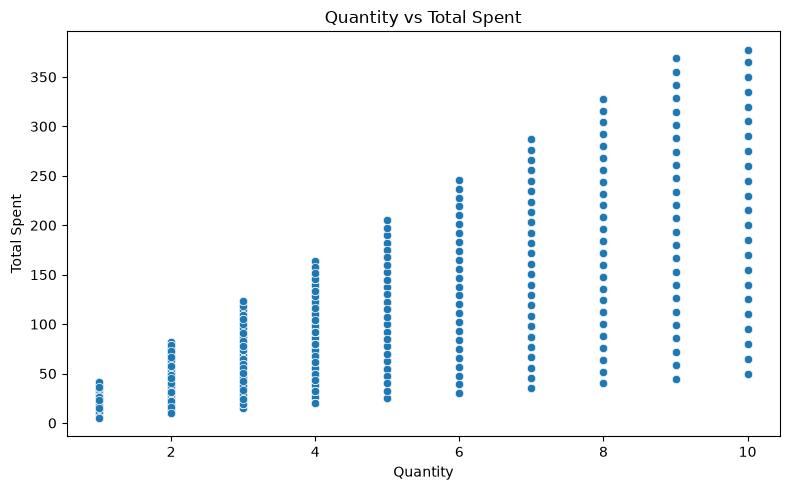

In [132]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Quantity",
    y="Total Spent"
)

plt.title("Quantity vs Total Spent")
plt.xlabel("Quantity")
plt.ylabel("Total Spent")

plt.tight_layout()
plt.show()

## Insight
* This indicates a relatively strong positive relationship.
* As quantity purchased increases, total spending generally tends to increase.
* The business can use this insight for bulk-buying offers and quantity-based promotions.